In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

# 시각화 스타일 설정
sns.set_theme(style="whitegrid", palette="Set2")

# 1. 데이터 로드 및 DataFrame 변환
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)

# 2. 데이터 구조 및 결측치/이상치 확인
print("=== 데이터 상위 5행 ===")
display(df.head())

print("\n=== 데이터 요약 정보 (결측치 확인) ===")
print(df.info())

print("\n=== 기초 통계량 ===")
display(df.describe())

print("\n=== 품종별 데이터 개수 (클래스 불균형 여부 확인) ===")
print(df['species'].value_counts())

=== 데이터 상위 5행 ===


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



=== 데이터 요약 정보 (결측치 확인) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   species            150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.1 KB
None

=== 기초 통계량 ===


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



=== 품종별 데이터 개수 (클래스 불균형 여부 확인) ===
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


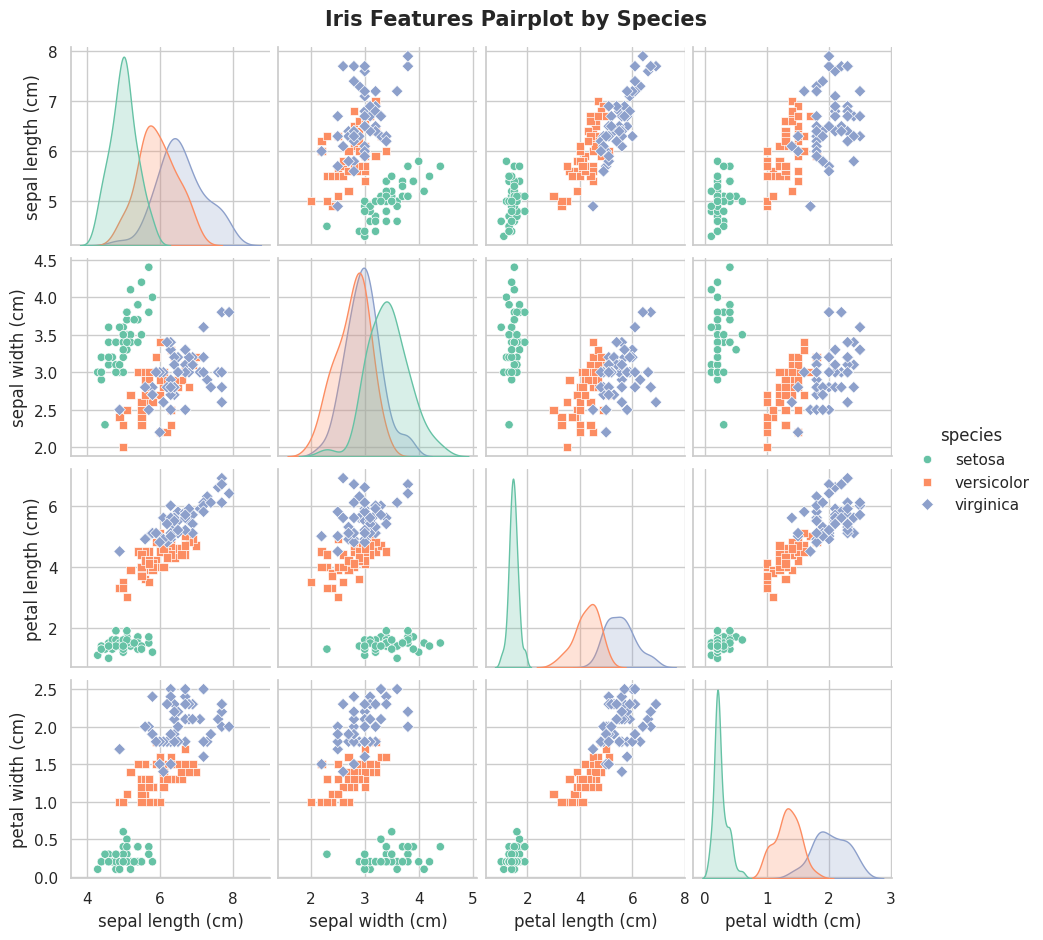

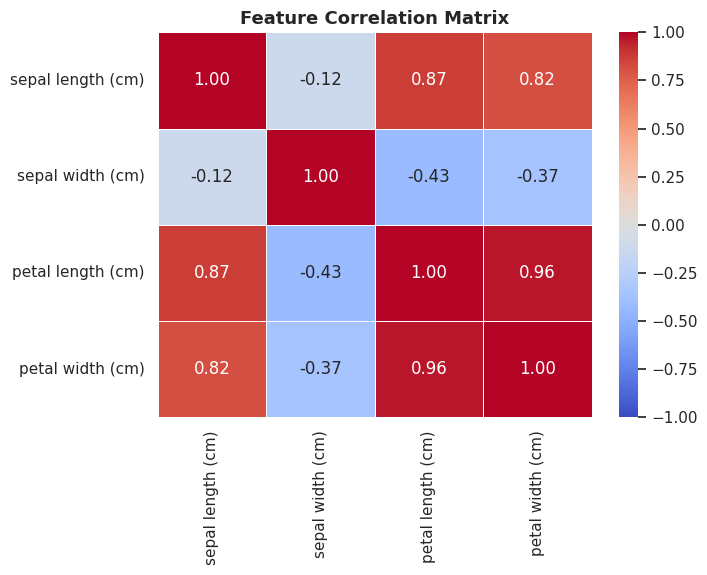

In [2]:
# 1. 변수 간 산점도 행렬 (Pairplot)
g = sns.pairplot(df, hue='species', markers=["o", "s", "D"], diag_kind="kde", height=2.3)
g.fig.suptitle("Iris Features Pairplot by Species", y=1.02, fontsize=15, fontweight='bold')
plt.show()

# 2. 수치형 변수 간 상관계수 히트맵
plt.figure(figsize=(7, 5))
corr = df.iloc[:, :4].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title("Feature Correlation Matrix", fontsize=13, fontweight='bold')
plt.show()

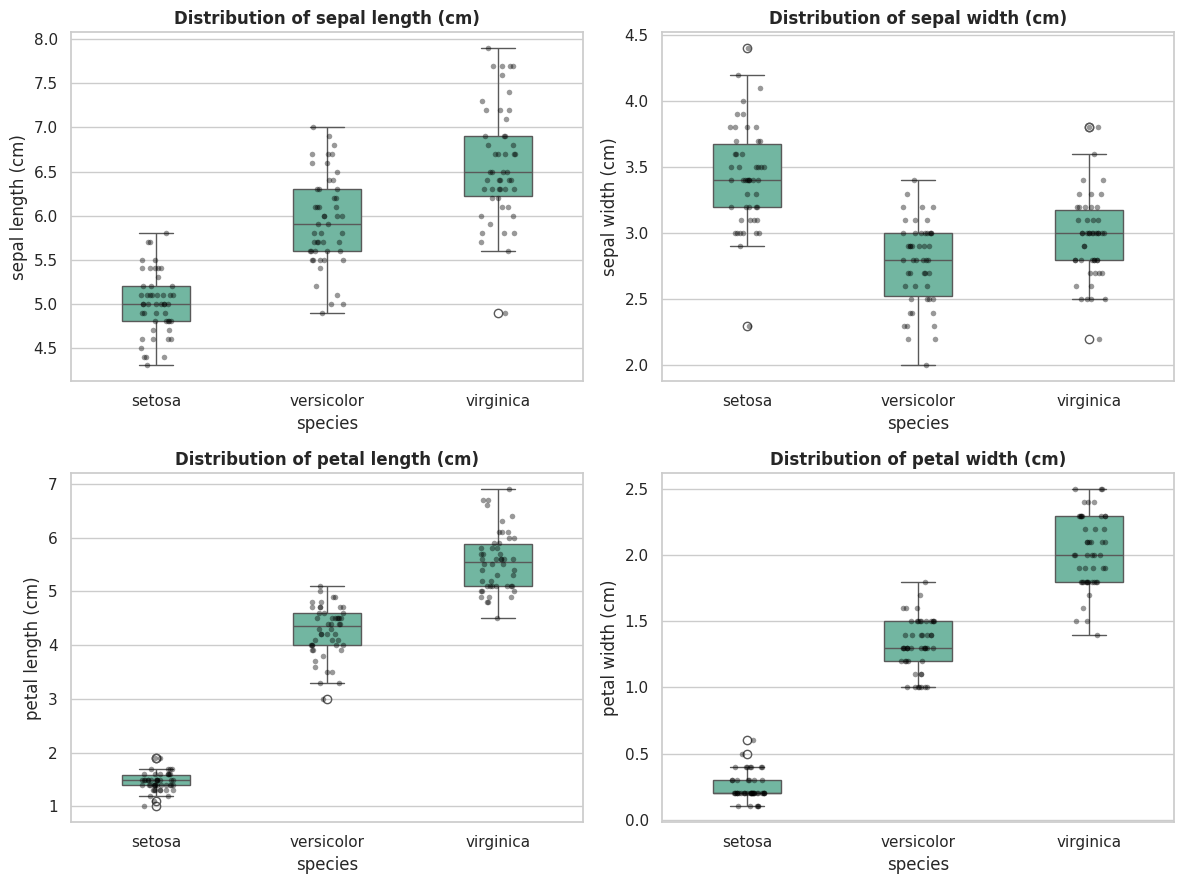

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
features = iris.feature_names

for idx, feature in enumerate(features):
    row, col = divmod(idx, 2)
    sns.boxplot(data=df, x='species', y=feature, ax=axes[row, col], width=0.4)
    sns.stripplot(data=df, x='species', y=feature, ax=axes[row, col], color='black', alpha=0.4, size=4)
    axes[row, col].set_title(f"Distribution of {feature}", fontweight='bold')

plt.tight_layout()
plt.show()

In [3]:
# EDA 및 시각화 결과,
# Iris 데이터셋은 petal 관련 변수(상관계수 0.96)가 품종 분류의 핵심 피처로 작용하며,
#Setosa는 선형 분리가 가능하고 Versicolor와 Virginica는 일부 경계 영역에서만 중첩됨을 확인함